# 1 · Data preparation

**Goal:** understand the SponsorWise dataset and turn it into the feature table the models learn from.

The dataset is synthetic, built to reflect Madhya Pradesh: **10,000 events**, each paired with **7 candidate brands**, so **70,000 rows**. Every row answers two questions:

1. How many people actually came? → `actual_attendance` (regression target)
2. Was the sponsorship worth it for the brand? → `feasible_to_sponsor` (0/1 classification target)

Steps: load → check quality → explore statistics and trends → remove leakage → build features → save.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 4)

RAW_FILE = "mp_sponsorwise_dataset.csv"
FEATURE_FILE = "mp_sponsorwise_ml_features.csv"

## 1. Load the data

In [2]:
df = pd.read_csv(RAW_FILE)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (70000, 41)


,event_id,brand_id,state,city,event_type,month,day_of_week,is_weekend,is_festive,festival_name,is_indoor,temperature,is_raining,humidity,venue_capacity,ticket_price,marketing_budget,organizer_reputation,lineup_quality,social_media_reach,past_events_organized,competing_events,predicted_attendance,predicted_attendance_rate,predicted_impressions,actual_attendance,actual_attendance_rate,event_rating,event_success,brand_category,brand_kpi,brand_city_focus,brand_annual_budget,brand_activation_maturity,fit_score,sponsor_amount,activation_quality,clutter_index,brand_lift,roi,feasible_to_sponsor
0,1,685,Madhya Pradesh,Ujjain,Food Festival,3,0,0,1,festive,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,6846,0.9974,28682,6865,1.0,4.29,1,Real Estate,hybrid,metro,1193012,0.746,0.3041,114490,0.9700,0.2792,2.143,-0.6719,0
1,1,609,Madhya Pradesh,Ujjain,Food Festival,3,0,0,1,festive,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,6846,0.9974,26520,6865,1.0,4.29,1,Fintech,hybrid,metro,2022412,0.395,0.2500,55563,0.8158,0.3478,2.390,-0.4607,0
2,1,217,Madhya Pradesh,Ujjain,Food Festival,3,0,0,1,festive,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,6846,0.9974,27430,6865,1.0,4.29,1,FMCG,awareness,all_mp,3073226,0.422,0.9975,167307,0.8554,0.3350,4.823,-0.9759,0
3,1,343,Madhya Pradesh,Ujjain,Food Festival,3,0,0,1,festive,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,6846,0.9974,28931,6865,1.0,4.29,1,Beauty/Personal Care,leads,all_mp,1195718,0.786,0.7790,143486,0.9700,0.1625,4.692,1.2899,1
4,1,755,Madhya Pradesh,Ujjain,Food Festival,3,0,0,1,festive,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,6846,0.9974,28644,6865,1.0,4.29,1,Automobile,hybrid,tier2,1540216,0.596,0.3999,144718,0.9637,0.1752,3.719,-0.6718,0


In [3]:
df.dtypes.value_counts()

int64      21
float64    13
object      7
Name: count, dtype: int64

## 2. Data quality
Missing values, duplicates, and whether the structure matches what we expect (7 brands per event).

In [4]:
print("Missing values in any column:", int(df.isna().sum().sum()))
print("Missing values by column (only columns with any):")
print(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values in any column: 0
Missing values by column (only columns with any):
Series([], dtype: int64)
Duplicate rows: 0


In [5]:
rows_per_event = df.groupby("event_id").size()
print("Events:", df["event_id"].nunique())
print("Brands in the pool:", df["brand_id"].nunique())
print("Rows per event:", rows_per_event.unique())

Events: 10000
Brands in the pool: 800
Rows per event: [7]


`festival_name` is only filled in for festive events, so its blanks are expected. It is dropped later because `is_festive` already carries that information.

## 3. Basic statistics

In [6]:
numeric_summary = df[["venue_capacity", "ticket_price", "marketing_budget", "sponsor_amount",
                      "social_media_reach", "actual_attendance"]].describe().round(1)
numeric_summary

,venue_capacity,ticket_price,marketing_budget,sponsor_amount,social_media_reach,actual_attendance
count,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0
mean,22135.2,610.4,25639.5,185211.8,3818.4,14864.7
std,17596.6,1245.2,28759.4,157508.1,6009.6,13015.4
min,395.0,0.0,2000.0,8000.0,100.0,203.0
25%,8300.2,103.0,9322.8,69347.8,661.0,5174.8
50%,17877.0,178.0,17278.5,134866.0,1842.5,11170.5
75%,31085.2,594.8,31412.0,248117.8,4711.2,20815.5
max,80000.0,9999.0,662931.0,750000.0,226118.0,80000.0


### Targets

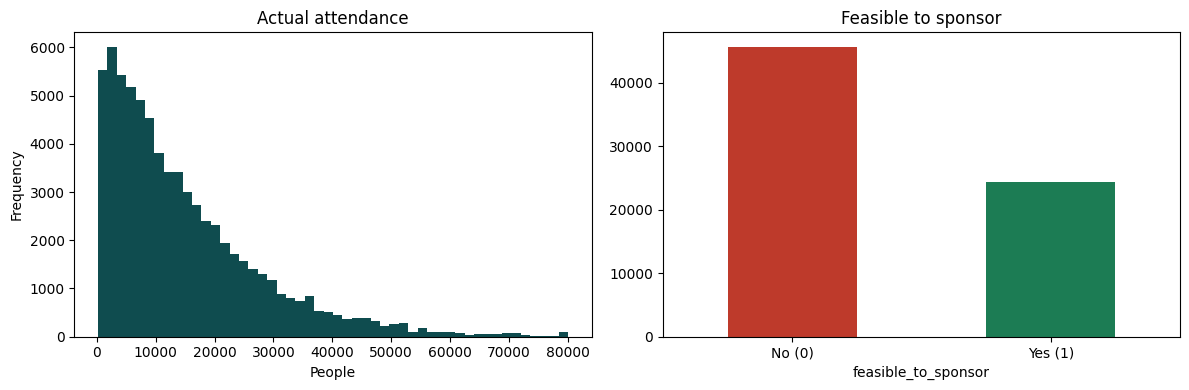

Feasible rate: 34.7%  ->  classes are imbalanced, about 1 yes for every 2 no


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["actual_attendance"].plot.hist(bins=50, ax=axes[0], color="#0F4C4F")
axes[0].set_title("Actual attendance")
axes[0].set_xlabel("People")

df["feasible_to_sponsor"].value_counts().sort_index().plot.bar(ax=axes[1], color=["#BE3A2B", "#1C7C54"])
axes[1].set_title("Feasible to sponsor")
axes[1].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
plt.tight_layout()
plt.show()

feasible_rate = df["feasible_to_sponsor"].mean()
print(f"Feasible rate: {feasible_rate:.1%}  ->  classes are imbalanced, about 1 yes for every 2 no")

## 4. Trends
Simple group averages show how the target changes with each factor.

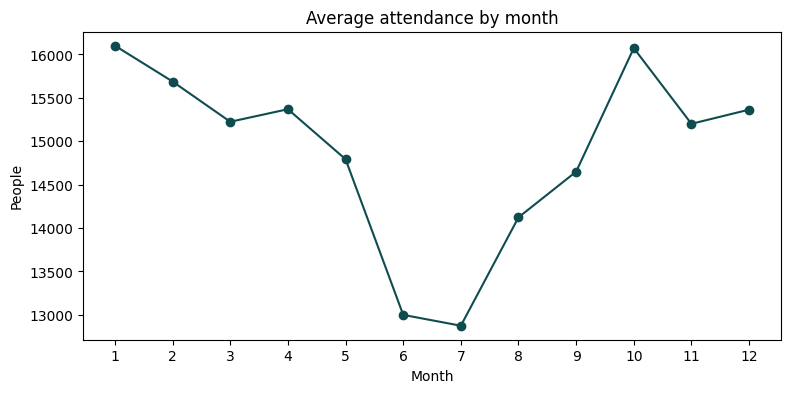

In [8]:
monthly = df.groupby("month")["actual_attendance"].mean()
monthly.plot(marker="o", color="#0F4C4F", title="Average attendance by month")
plt.xlabel("Month")
plt.ylabel("People")
plt.xticks(range(1, 13))
plt.show()

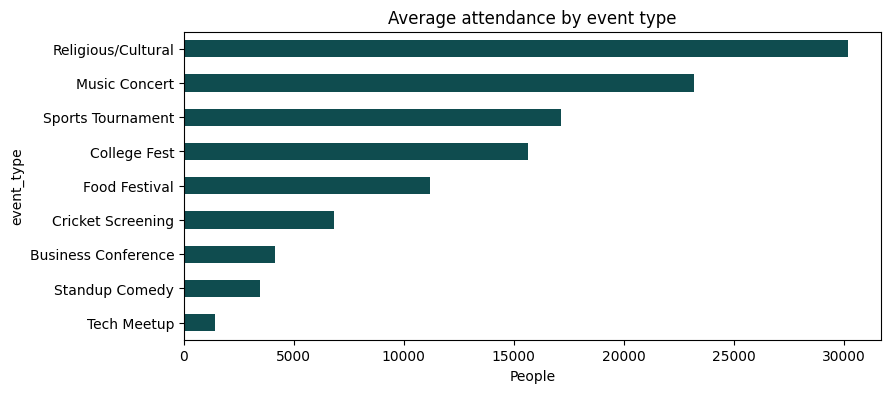

In [9]:
by_type = df.groupby("event_type")["actual_attendance"].mean().sort_values()
by_type.plot.barh(color="#0F4C4F", title="Average attendance by event type")
plt.xlabel("People")
plt.show()

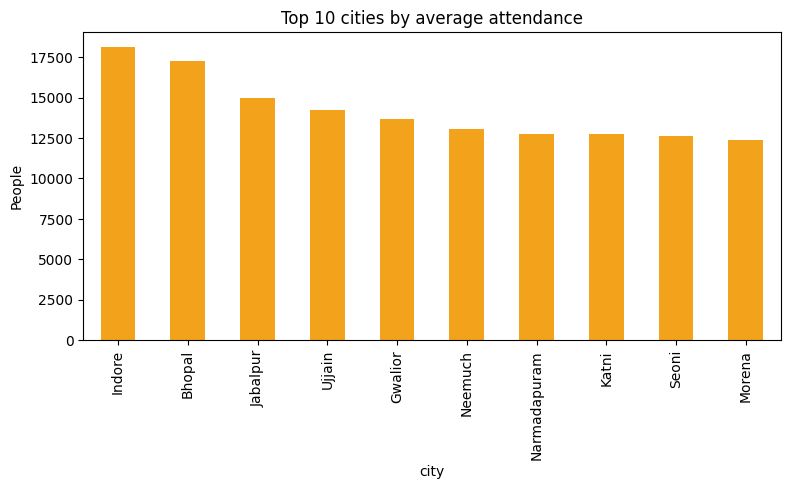

In [10]:
by_city = df.groupby("city")["actual_attendance"].mean().sort_values(ascending=False).head(10)
by_city.plot.bar(color="#F2A31B", title="Top 10 cities by average attendance")
plt.ylabel("People")
plt.show()

In [11]:
weekend_effect = df.groupby("is_weekend")["actual_attendance"].mean().rename({0: "Weekday", 1: "Weekend"})
festive_effect = df.groupby("is_festive")["actual_attendance"].mean().rename({0: "Not festive", 1: "Festive"})
pd.concat([weekend_effect, festive_effect]).round(0)

Weekday        14517.0
Weekend        15777.0
Not festive    11271.0
Festive        22208.0
Name: actual_attendance, dtype: float64

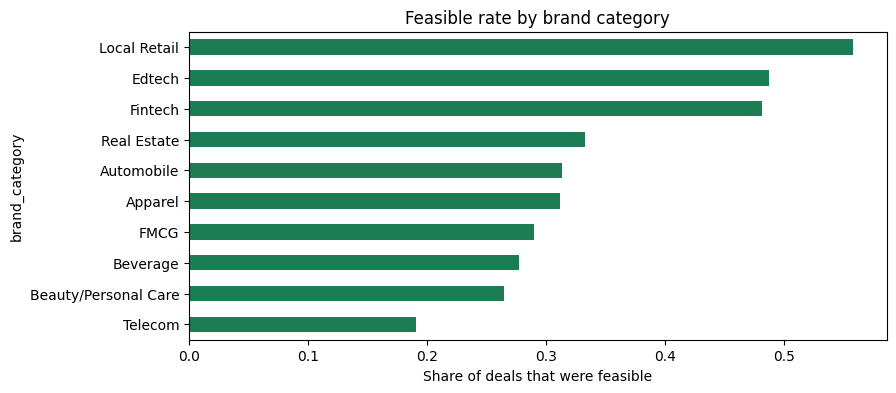

In [12]:
by_brand = df.groupby("brand_category")["feasible_to_sponsor"].mean().sort_values()
by_brand.plot.barh(color="#1C7C54", title="Feasible rate by brand category")
plt.xlabel("Share of deals that were feasible")
plt.show()

**Brand-event fit matters:** as `fit_score` rises, far more deals are feasible.

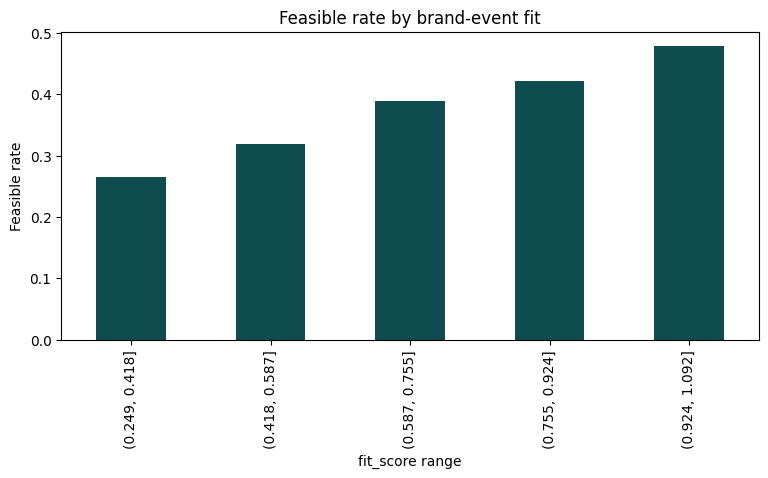

In [13]:
fit_bands = pd.cut(df["fit_score"], bins=5)
df.groupby(fit_bands, observed=True)["feasible_to_sponsor"].mean().plot.bar(
    color="#0F4C4F", title="Feasible rate by brand-event fit")
plt.xlabel("fit_score range")
plt.ylabel("Feasible rate")
plt.show()

**Price per person matters:** the sponsorship amount divided by attendance is what a brand really pays for each person reached.

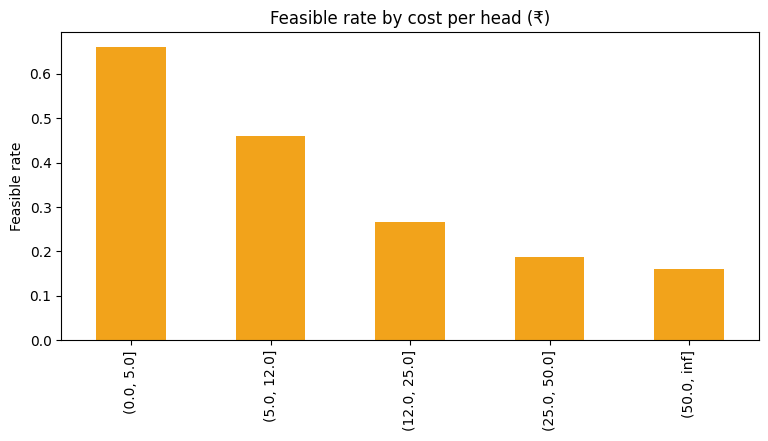

In [14]:
cost_per_head = df["sponsor_amount"] / df["actual_attendance"].clip(lower=1)
cost_bands = pd.cut(cost_per_head, bins=[0, 5, 12, 25, 50, float("inf")])
df.groupby(cost_bands, observed=True)["feasible_to_sponsor"].mean().plot.bar(
    color="#F2A31B", title="Feasible rate by cost per head (₹)")
plt.ylabel("Feasible rate")
plt.show()

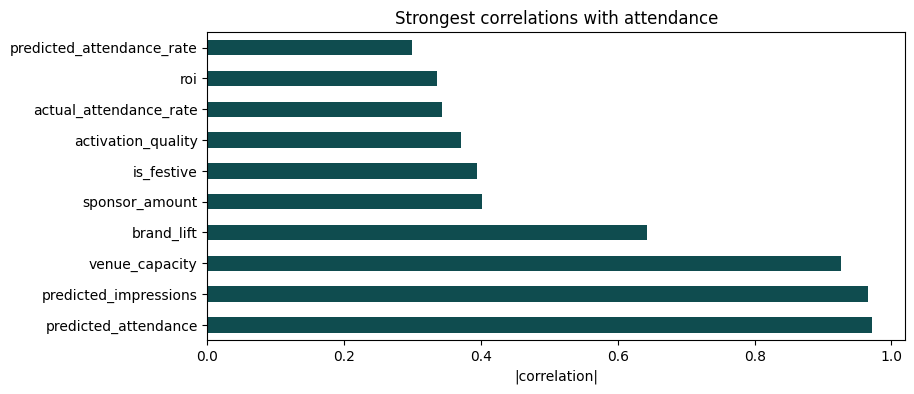

In [15]:
correlations = df.select_dtypes("number").corr()["actual_attendance"].drop("actual_attendance")
correlations.abs().sort_values(ascending=False).head(10).plot.barh(
    color="#0F4C4F", title="Strongest correlations with attendance")
plt.xlabel("|correlation|")
plt.show()

## 5. Remove identifiers and leakage

Two kinds of column must not be model inputs:

* **Identifiers** say nothing about an event: `event_id`, `brand_id`, `state` (always Madhya Pradesh), `festival_name` (covered by `is_festive`).
* **Leakage**: values only known *after* the event. A model trained on them looks brilliant in testing and is useless in real life, because none of them exist when a brand is deciding.

| Column | Why it leaks |
|---|---|
| `actual_attendance_rate` | Computed from the attendance we are predicting |
| `event_rating`, `event_success` | Known only after the event |
| `activation_quality`, `clutter_index`, `brand_lift`, `roi` | Measured during or after the sponsorship |
| `predicted_attendance`, `predicted_attendance_rate`, `predicted_impressions` | Outputs of the data generator, not real inputs |

In [16]:
ID_COLUMNS = ["event_id", "brand_id", "state", "festival_name"]
LEAKAGE_COLUMNS = [
    "actual_attendance_rate", "event_rating", "event_success",
    "activation_quality", "clutter_index", "brand_lift", "roi",
    "predicted_attendance", "predicted_attendance_rate", "predicted_impressions",
]
clean = df.drop(columns=ID_COLUMNS + LEAKAGE_COLUMNS)
print("Columns left:", clean.shape[1])

Columns left: 27


## 6. Build the features

Categories (city, event type…) have no natural order, so each becomes yes/no columns with **one-hot encoding**. `drop_first=True` removes one value per category, because the others already imply it. The dropped value is the **reference**: all zeros means Bhopal, Business Conference, Apparel, awareness, or all of MP.

In [17]:
CATEGORY_COLUMNS = ["city", "event_type", "brand_category", "brand_kpi", "brand_city_focus"]
TARGETS = ["actual_attendance", "feasible_to_sponsor"]

features = pd.get_dummies(clean, columns=CATEGORY_COLUMNS, drop_first=True)
yes_no_columns = features.select_dtypes(include="bool").columns
features[yes_no_columns] = features[yes_no_columns].astype(int)

# Inputs first, targets last
input_columns = [column for column in features.columns if column not in TARGETS]
features = features[input_columns + TARGETS]

print("Input features:", len(input_columns))
print("Reference values (no column):",
      {column: sorted(clean[column].unique())[0] for column in CATEGORY_COLUMNS})

Input features: 67
Reference values (no column): {'city': 'Bhopal', 'event_type': 'Business Conference', 'brand_category': 'Apparel', 'brand_kpi': 'awareness', 'brand_city_focus': 'all_mp'}


In [18]:
assert len(input_columns) == 67, "The service expects exactly 67 input features"
features.head()

,month,day_of_week,is_weekend,is_festive,is_indoor,temperature,is_raining,humidity,venue_capacity,ticket_price,marketing_budget,organizer_reputation,lineup_quality,social_media_reach,past_events_organized,competing_events,brand_annual_budget,brand_activation_maturity,fit_score,sponsor_amount,city_Burhanpur,city_Chhindwara,city_Damoh,city_Dewas,city_Gwalior,...,event_type_College Fest,event_type_Cricket Screening,event_type_Food Festival,event_type_Music Concert,event_type_Religious/Cultural,event_type_Sports Tournament,event_type_Standup Comedy,event_type_Tech Meetup,brand_category_Automobile,brand_category_Beauty/Personal Care,brand_category_Beverage,brand_category_Edtech,brand_category_FMCG,brand_category_Fintech,brand_category_Local Retail,brand_category_Real Estate,brand_category_Telecom,brand_kpi_hybrid,brand_kpi_leads,brand_kpi_sales,brand_city_focus_metro,brand_city_focus_pilgrimage,brand_city_focus_tier2,actual_attendance,feasible_to_sponsor
0,3,0,0,1,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,1193012,0.746,0.3041,114490,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,6865,0
1,3,0,0,1,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,2022412,0.395,0.2500,55563,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,6865,0
2,3,0,0,1,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,3073226,0.422,0.9975,167307,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,6865,0
3,3,0,0,1,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,1195718,0.786,0.7790,143486,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,6865,1
4,3,0,0,1,0,28.31,0,25.91,6865,200,30303,0.727,0.391,2974,14,1,1540216,0.596,0.3999,144718,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,6865,0


## 7. Save

In [19]:
features.to_csv(FEATURE_FILE, index=False)
print("Saved", FEATURE_FILE, features.shape)

Saved mp_sponsorwise_ml_features.csv (70000, 69)
